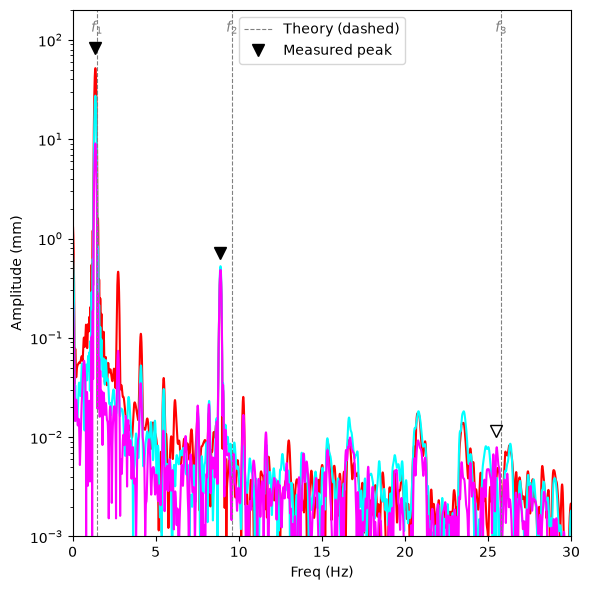

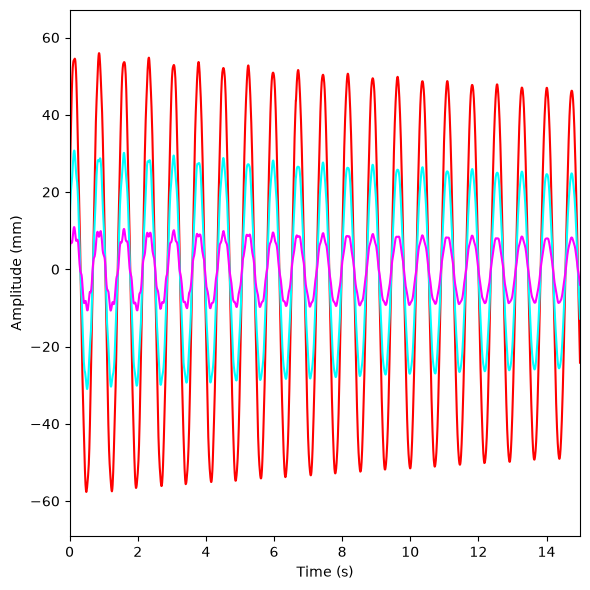

a 0.010046843345008908
b 0.011650732341680277
c 0.016267991433386336


In [2]:
from numpy.fft import fft
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import scipy

df = pd.read_csv("../data/weights_A_LEFT_B_MIDDLE_C_RIGHT.txt", sep="\t", skiprows=2)


df = df.dropna(axis=1, how="all")

weights = ["a", "b", "c"]
data = {w: {} for w in weights}

t = df["t"]

sr = 240
n_fft=2**18

for w in weights:
        
        y = df[w + "y"]
        N = len(y) # use original non padded length
        norm_y = (np.array(y) - np.mean(y))*1000
        data[w]["norm_y"] = norm_y
        window = np.hanning(N)
        X = fft(norm_y * window, n=n_fft)
        X *= 2 / np.sum(window)   # required bc more samples would make it misleadingly higher. 2 bc of neg freqs# replaces 2 / N when windowed
        n = np.arange(n_fft)
        T = n_fft/sr
        freq = n/T
        data[w]["freqs"] = freq
        data[w]["amplitudes"] = np.abs(X)
        
plt.figure(figsize = (6, 6))
colors = ['red', 'cyan', 'fuchsia']
for w, c in zip(weights, colors):
        plt.plot(data[w]["freqs"], data[w]["amplitudes"], c)
plt.xlabel('Freq (Hz)')
plt.ylabel('Amplitude (mm)')
plt.yscale('log')
plt.xlim(0, 30)
plt.ylim(1e-3, 200)

modes_meas = [(1.37, "a"), (8.90, "a"), (25.5, "c")]
modes_theory = [1.47, 9.60, 25.80]
for idx, (f_th, label) in enumerate(zip(modes_theory, [r"$f_1$", r"$f_2$", r"$f_3$"])):
        plt.axvline(f_th, ls="--", color="gray", lw=0.8, label="Theory (dashed)" if idx == 0 else None)
        plt.text(f_th, 120, label, ha="center", color="gray")
for idx, (f, w) in enumerate(modes_meas):
        freqs, amps = data[w]["freqs"], data[w]["amplitudes"]
        i = np.argmin(np.abs(freqs - f))
        plt.plot(f, amps[i] * 1.6, "v", color="black", mfc="none" if f == 25.5 else "black", markersize=8, label="Measured peak" if idx == 0 else None)
plt.legend()
plt.tight_layout()
plt.savefig("../plots/fft_disp_log_dec_three_masses_fft_plot.png", dpi=300)

plt.figure(figsize = (6, 6))
for w, c in zip(weights, colors):
        plt.plot(t, data[w]["norm_y"], c)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (mm)')
rescale = 1.2
plt.ylim(min(data['a']["norm_y"])*rescale, max(data['a']["norm_y"])* rescale)
plt.xlim(0, max(t))
plt.tight_layout()
plt.savefig("../plots/fft_disp_log_dec_three_masses_time_plot.png", dpi=300)

plt.show()


# Logarithmic decrement:
# https://wikipedia.org

# Find peaks:
# https://scipy.org

def find_log_dc(weight_norm_y):
        peaks, _ = scipy.signal.find_peaks(weight_norm_y, height=0, threshold=None, distance=140, prominence=5, width=None, wlen=None, rel_height=0.5, plateau_size=None)

        max_pos_peak = weight_norm_y[peaks[0]]
        min_pos_peak = weight_norm_y[peaks[0]]
        max_pos_peak_i = 0
        min_pos_peak_i = 0

        for i, peak in enumerate(peaks):

                if weight_norm_y[peak] > max_pos_peak:
                        max_pos_peak = weight_norm_y[peak]
                        max_pos_peak_i = i
                if weight_norm_y[peak] < min_pos_peak:
                        min_pos_peak = weight_norm_y[peak]
                        min_pos_peak_i = i
        periods_in_between = abs(max_pos_peak_i - min_pos_peak_i)

        def log_dec(n, first_peak_overshoot, second_peak_overshoot):
                return (1/n) * np.log(first_peak_overshoot / second_peak_overshoot)

        return log_dec(periods_in_between, max_pos_peak, min_pos_peak)

for w in weights:
        print(w, find_log_dc(data[w]["norm_y"]))